In [1]:
%pip install kagglehub

In [2]:
import kagglehub
kagglehub.login()
# KGAT_75a9dd51fa8adbf133da815aef6c0963

Kaggle credentials set.
Kaggle credentials successfully validated.


In [3]:
# Download latest version
path = kagglehub.competition_download('che-1147-2026')

print("Path to competition files:", path)

100%|██████████| 5.31M/5.31M [00:00<00:00, 66.5MB/s]

Extracting files...


Path to competition files: /root/.cache/kagglehub/competitions/che-1147-2026


In [4]:
import os
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xgboost as xgb

from sklearn.model_selection import (
    train_test_split,
    KFold,
    cross_validate,
    RandomizedSearchCV
)

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

from scipy.stats import randint, uniform, loguniform

# ============================
# 1. Load data
# ============================

train = pd.read_csv(os.path.join(path, "train.csv"))
test = pd.read_csv(os.path.join(path, "test.csv"))

TARGET = "CO2 uptake at 0.15 bar and 298K"

# ============================
# 2. Select common features
# ============================

feature_cols = [
    col for col in test.columns
    if col != "MOFname" and col in train.columns
]

X = train[feature_cols].copy()
y = train[TARGET].copy()
X_test = test[feature_cols].copy()

# ============================
# 3. Clean feature names
# ============================

def clean_feature_names(columns):
    return [
        re.sub(r"[\[\]<]", "_", str(col))
        for col in columns
    ]

clean_cols = clean_feature_names(feature_cols)

# Check that cleaning does not create duplicate names
assert len(clean_cols) == len(set(clean_cols)), \
    "Duplicate names after cleaning!"

X.columns = clean_cols
X_test.columns = clean_cols

# ============================
# 4. Check data
# ============================

assert X.columns.equals(X_test.columns)

assert X.columns.is_unique

assert np.isfinite(y.to_numpy()).all(), \
    "Target contains NaN or infinite values"

# Replace infinity with NaN
X = X.replace([np.inf, -np.inf], np.nan)
X_test = X_test.replace([np.inf, -np.inf], np.nan)

print("X:", X.shape)
print("y:", y.shape)
print("X_test:", X_test.shape)

print("Missing in X:", X.isna().sum().sum())
print("Missing in X_test:", X_test.isna().sum().sum())

X: (5014, 272)
y: (5014,)
X_test: (2000, 272)
Missing in X: 1
Missing in X_test: 0


In [5]:
X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=0
)

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Kaggle Test:", X_test.shape)

Training: (4011, 272)
Validation: (1003, 272)
Kaggle Test: (2000, 272)


In [7]:
### XGBoost

In [6]:
xgb_model = xgb.XGBRegressor(
    n_estimators=500,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    min_child_weight=5,
    reg_alpha=0.1,
    reg_lambda=5,
    objective="reg:squarederror",
    tree_method="hist",
    random_state=42,
    n_jobs=4
)

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scores = cross_validate(
    xgb_model,
    X_train,
    y_train,
    cv=cv,
    scoring={
        "MAE": "neg_mean_absolute_error",
        "RMSE": "neg_root_mean_squared_error",
        "R2": "r2"
    },
    return_train_score=True,
    n_jobs=1,
    error_score="raise"
)

print("Train MAE:", -scores["train_MAE"].mean())
print("CV MAE:", -scores["test_MAE"].mean())
print("CV RMSE:", -scores["test_RMSE"].mean())
print("CV R2:", scores["test_R2"].mean())

Train MAE: 0.33009392882979627
CV MAE: 0.6247566882606301
CV RMSE: 0.9051866011625194
CV R2: 0.6523084432296126


In [8]:
param_distributions = {
    "n_estimators": randint(200, 1001),
    "max_depth": randint(2, 8),
    "learning_rate": loguniform(0.01, 0.15),
    "subsample": uniform(0.6, 0.4),
    "colsample_bytree": uniform(0.6, 0.4),
    "min_child_weight": randint(2, 16),
    "reg_alpha": loguniform(0.001, 10),
    "reg_lambda": loguniform(0.1, 100)
}

search_xgb = RandomizedSearchCV(
    estimator=xgb_model,
    param_distributions=param_distributions,
    n_iter=30,
    scoring="neg_mean_absolute_error",
    cv=cv,
    n_jobs=-1,
    random_state=42,
    verbose=1,
    error_score="raise"
)

search_xgb.fit(X_train, y_train)

print("\nBest parameters:")
print(search_xgb.best_params_)

print("\nBest CV MAE:", -search_xgb.best_score_)

Fitting 5 folds for each of 30 candidates, totalling 150 fits

Best parameters:
{'colsample_bytree': np.float64(0.8165791895310264), 'learning_rate': np.float64(0.06581213050794947), 'max_depth': 5, 'min_child_weight': 11, 'n_estimators': 823, 'reg_alpha': np.float64(0.16626592254031872), 'reg_lambda': np.float64(3.881072316409481), 'subsample': np.float64(0.6967409163601807)}

Best CV MAE: 0.5836017063331441


In [9]:
best_xgb = search_xgb.best_estimator_

y_train_pred = best_xgb.predict(X_train)
y_val_pred = best_xgb.predict(X_val)

def evaluate_model(y_true, y_pred, name):
    print(f"\n{name}")
    print("MAE:", mean_absolute_error(y_true, y_pred))
    print("RMSE:", np.sqrt(mean_squared_error(y_true, y_pred)))
    print("R2:", r2_score(y_true, y_pred))

evaluate_model(y_train, y_train_pred, "Train")
evaluate_model(y_val, y_val_pred, "Validation")


Train
MAE: 0.11656579963119201
RMSE: 0.1706232434794969
R2: 0.9877256456467545

Validation
MAE: 0.5422777470251287
RMSE: 0.8225629927896833
R2: 0.7277061195432397


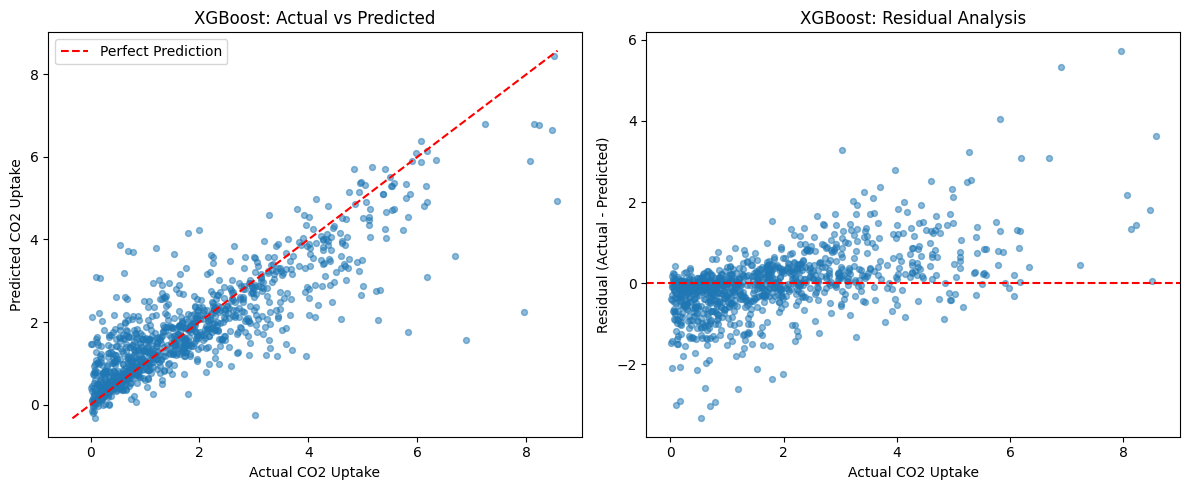

In [10]:
residuals = y_val.to_numpy() - y_val_pred

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Actual vs Predicted
axes[0].scatter(
    y_val,
    y_val_pred,
    alpha=0.5,
    s=18
)

limits = [
    min(y_val.min(), y_val_pred.min()),
    max(y_val.max(), y_val_pred.max())
]

axes[0].plot(
    limits,
    limits,
    "r--",
    label="Perfect Prediction"
)

axes[0].set_xlabel("Actual CO2 Uptake")
axes[0].set_ylabel("Predicted CO2 Uptake")
axes[0].set_title("XGBoost: Actual vs Predicted")
axes[0].legend()

# Residual
axes[1].scatter(
    y_val,
    residuals,
    alpha=0.5,
    s=18
)

axes[1].axhline(0, color="red", linestyle="--")
axes[1].set_xlabel("Actual CO2 Uptake")
axes[1].set_ylabel("Residual (Actual - Predicted)")
axes[1].set_title("XGBoost: Residual Analysis")

plt.tight_layout()
plt.show()

In [11]:
error_df = pd.DataFrame({
    "Actual": y_val.to_numpy(),
    "Predicted": y_val_pred
})

error_df["Residual"] = (
    error_df["Actual"] - error_df["Predicted"]
)

error_df["Absolute_Error"] = (
    error_df["Residual"].abs()
)

bins = [-np.inf, 1, 2, 3, 4, 5, np.inf]
labels = ["<1", "1–2", "2–3", "3–4", "4–5", "≥5"]

error_df["Uptake_Range"] = pd.cut(
    error_df["Actual"],
    bins=bins,
    labels=labels
)

error_summary = error_df.groupby(
    "Uptake_Range",
    observed=True
).agg(
    Count=("Actual", "count"),
    MAE=("Absolute_Error", "mean"),
    Bias=("Residual", "mean")
)

display(error_summary)

,Count,MAE,Bias
Uptake_Range,,,
<1,384,0.461068,-0.399523
1–2,254,0.423173,-0.157042
2–3,158,0.469184,0.256168
3–4,91,0.731463,0.546768
4–5,66,0.872578,0.740487
≥5,50,1.221681,1.156998


In [12]:
### Catboost

In [13]:
%pip install catboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 8.2 MB/s eta 0:00:00


In [14]:
from catboost import CatBoostRegressor
from sklearn.model_selection import KFold, cross_validate
import pandas as pd

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cat_models = {
    "CatBoost RMSE": CatBoostRegressor(
        iterations=800,
        depth=5,
        learning_rate=0.04,
        l2_leaf_reg=5,
        loss_function="RMSE",
        verbose=False,
        thread_count=4,
        random_seed=42
    ),

    "CatBoost MAE": CatBoostRegressor(
        iterations=800,
        depth=5,
        learning_rate=0.04,
        l2_leaf_reg=5,
        loss_function="MAE",
        verbose=False,
        thread_count=4,
        random_seed=42
    )
}

results = []

for name, model in cat_models.items():

    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring={
            "MAE": "neg_mean_absolute_error",
            "RMSE": "neg_root_mean_squared_error",
            "R2": "r2"
        },
        return_train_score=True,
        n_jobs=1,
        error_score="raise"
    )

    results.append({
        "Model": name,
        "Train MAE": -scores["train_MAE"].mean(),
        "CV MAE": -scores["test_MAE"].mean(),
        "CV RMSE": -scores["test_RMSE"].mean(),
        "CV R2": scores["test_R2"].mean()
    })

results_df = pd.DataFrame(results)

display(results_df.sort_values("CV MAE"))

,Model,Train MAE,CV MAE,CV RMSE,CV R2
0,CatBoost RMSE,0.446514,0.655896,0.932271,0.631499
1,CatBoost MAE,0.491641,0.679329,1.018560,0.560364
